# Extraction de Keywords

In [1]:
import os
import yake

## Extraire les mots clés d'un document avec Yake

In [2]:
# Instantier l'extracteur de mots clés
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)
kw_extractor

In [5]:
# Lister les Fichiers
year = 1933

data_path = "../../txt/"
files = [f for f in os.listdir(data_path) if f.endswith('.txt') and f.split('_')[2].split('-')[0] == str(year)]

In [6]:
# Imprimer le nombre de fichiers identifiés
len(files)

100

In [7]:
# Les dix premiers fichiers
files[:10]

['KB_JB838_1933-01-01_01-00005.txt',
 'KB_JB838_1933-01-04_01-00003.txt',
 'KB_JB838_1933-01-05_01-00004.txt',
 'KB_JB838_1933-01-07_01-00001.txt',
 'KB_JB838_1933-01-09_01-00010.txt',
 'KB_JB838_1933-01-11_01-00010.txt',
 'KB_JB838_1933-01-17_01-00012.txt',
 'KB_JB838_1933-01-19_01-00002.txt',
 'KB_JB838_1933-01-21_01-00012.txt',
 'KB_JB838_1933-01-27_01-00010.txt']

In [8]:
# Choisir un fichier
this_file = files[0]
this_file

'KB_JB838_1933-01-01_01-00005.txt'

In [9]:
# Récupérer le texte du fichier
text = open(os.path.join(data_path, this_file), 'r', encoding='utf-8').read()
text[:500]

"1er JANVIER *** LE SOIR — COLLISION ENTRE ATTELAGE ET AUTO. A Waerschoot; une violente collision •'est produite entre un attelage et l’auto d’une brasserie gantoise. Le conducteur du dernier véhicule, Arthur Engels, domicilié à Gand, fut sérieusement blessé à la tête et se plaint de douleurs internes. M. C. (P.) —LA RUCHE D’OR, 33, rue au Beurre. Pains d’épices au miel fin d’ancienne réputation. fourrés au melon confit. 29261 — FERMES INCENDIÉES. A Kieldrecht, un incendie, dont les causes sont i"

In [10]:
# Extraire les mots clés de ce texte
keywords = kw_extractor.extract_keywords(text)
keywords

[('demeurant rue', np.float64(0.009831803790083594)),
 ('petit Jean', np.float64(0.010290757120488424)),
 ('ans', np.float64(0.011429284006588316)),
 ('rue', np.float64(0.011804788455962065)),
 ('Jean', np.float64(0.012535257929432126)),
 ('Lechanchy', np.float64(0.016036942380873165)),
 ('FRANCS', np.float64(0.018842705813634664)),
 ('qu’il', np.float64(0.0188962945110708)),
 ('d’un', np.float64(0.021093885335674693)),
 ('ATTELAGE ET AUTO', np.float64(0.022213896964615246)),
 ('demeurant', np.float64(0.02313150448905217)),
 ('mort', np.float64(0.024350807357516588)),
 ('MENU', np.float64(0.026544832457301066)),
 ('ENFANTS ADMIS', np.float64(0.028444632672202482)),
 ('JANVIER', np.float64(0.02881988888788763)),
 ('semaine', np.float64(0.032610173215856554)),
 ('fut', np.float64(0.035837486129596294)),
 ('enfants', np.float64(0.03725829348812355)),
 ('demeurant rue Kronenburg', np.float64(0.03883397649722853)),
 ('demeurant rue Bervoets', np.float64(0.039199696829966546)),
 ('Mme', np.f

In [11]:
# Ne garder que les bigrammes
kept = []
for kw, score in keywords:
    words = kw.split()
    if len(words) == 2:
        kept.append(kw)
kept

['demeurant rue',
 'petit Jean',
 'ENFANTS ADMIS',
 'NOCES D’OR',
 'Camille Hulin',
 'cadavre d’un',
 'rue Neuve']

In [12]:
for f in sorted(files):
    text = open(os.path.join(data_path, f), 'r', encoding="utf-8").read()
    keywords = kw_extractor.extract_keywords(text)
    kept = []
    for kw, score in keywords:
        words = kw.split()
        if len(words) == 2:
            kept.append(kw)
    print(f"{f} mentions these keywords: {', '.join(kept)}...")

KB_JB838_1933-01-01_01-00005.txt mentions these keywords: demeurant rue, petit Jean, ENFANTS ADMIS, NOCES D’OR, Camille Hulin, cadavre d’un, rue Neuve...
KB_JB838_1933-01-04_01-00003.txt mentions these keywords: troupes chinoises, troupes japonaises, Janvier Mars, Novembre Janvier, D’autre part, Camille Huysmans, gouvernement japonais, Londres LONDRES, Chan Haï...
KB_JB838_1933-01-05_01-00004.txt mentions these keywords: tonnes Moorsom, NOTES PARISIENNES, Mme Balthazar, Moorsom net, Mme Linz, Mme Michaud, mardi soir, Procureur Général, grand artiste...
KB_JB838_1933-01-07_01-00001.txt mentions these keywords: Bovesse qu’il, Pacte Briand-Keliogg, Centimes ABONNEMENTS, Albert Devèze...
KB_JB838_1933-01-09_01-00010.txt mentions these keywords: FILS SPÉCIAUX, Agence Rossel, bas prix, rue Joseph...
KB_JB838_1933-01-11_01-00010.txt mentions these keywords: Agence Rossel, bel app, LOUER app, Prix mod, RUE AYEZ, louer bel, belle maison, conf. mod, AVENUE LOUISE, PORTE LOUISE, Bel Appart...
KB_

# Nuages de mots

# Nuages de mots

## Imports et stopwords

In [13]:
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\gaeta\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [14]:
# Stopwords (Idem que dans s1)
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem", "brux", "louer", "app", "appart", "conf", "gar", "bain", "notaire", "comm", "int", "aven", "cond", "mod", "sal", "pièces", "mois", "ans", "année", "jours", "jour", "heures", "heure", "soir", "midi", "matin",
       "temps", "quart", "lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche", "janvier", "mars", "avril", "mai", "juin", "juillet", "août",
       "septembre", "octobre", "novembre", "décembre","rue", "louer", "prix", "maison", "francs", "app", "appart", "conf", "confort",
       "ecr", "ecrire", "écrire", "vend", "vendre", "vente", "brux", "agence", "notaire","chauf", "jard", "jardin", "cond", "conditions", "adr", "adresser", "gar", "garage", "rez", "bel", "étage", "chamb", "chambre", "sal", "salle", "bain", "cave", "villa", "mod", "moderne", "culs", "gaz", "eau", "terrain", "mètres", "pièces", "cherche", "demande", "avenue", "aven", "chaussée", "place", "comm", "int", "pers", "occasion", "vis", "mme", "cour", "cours", "saint", "nord", "tél", "télé", "télép", "téléphone",
       "enf", "ler", "pet", "dès", "dés", "hui", "aujourd", "voici", "alors", "fois", "chaque", "puis", "vient", "voir", "donné", "rien", "cas", "mal", "quatre", "sup",
       "rent", "rentier", "garni", "pens", "pension", "ares", "cyl", "com", "min", "chauff","terr", "frais", "gros", "bons", "bas", "nom", "ordre", "vue", "elles", "leurs",
       "celui", "ceux", "seul", "point", "points", "places", "fin", "effet", "pièce", "contenant", "renseignements", "référ", "façade", "pied", "partir", "terre"]
sw = set(sw)


## Créer un fichier contenant le texte de tous les journaux d'une année donnée

In [15]:
# Choisir une année
year = 1933

In [16]:
# Lister les fichiers de cette année
data_path = '..'
txt_path = '../../txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and str(year) in f]
len(txts)

100

In [17]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [18]:
# Compter le nombre d'éléments (=fichiers) dans la liste
len(content_list)

100

In [19]:
# Imprimer les 200 premiers caractères du contenu du premier fichier
content_list[0][0:200]

"1er JANVIER *** LE SOIR — COLLISION ENTRE ATTELAGE ET AUTO. A Waerschoot; une violente collision •'est produite entre un attelage et l’auto d’une brasserie gantoise. Le conducteur du dernier véhicule,"

In [20]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = '../tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [21]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

"1er JANVIER *** LE SOIR — COLLISION ENTRE ATTELAGE ET AUTO. A Waerschoot; une violente collision •'est produite entre un attelage et l’auto d’une brasserie gantoise. Le conducteur du dernier véhicule, Arthur Engels, domicilié à Gand, fut sérieusement blessé à la tête et se plaint de douleurs internes. M. C. (P.) —LA RUCHE D’OR, 33, rue au Beurre. Pains d’épices au miel fin d’ancienne réputation. fourrés au melon confit. 29261 — FERMES INCENDIÉES. A Kieldrecht, un incendie, dont les causes sont i"

## Nettoyer le fichier à l'aide d'une fonction de nettoyage

### Créer la fonction de nettoyage (à adapter)

In [22]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

### Appliquer la fonction sur le fichier complet de l'année

In [23]:
clean_text(year, folder=temp_path)

'Output has been written in ../tmp/1933_clean.txt!'

In [24]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'COLLISION ATTELAGE AUTO WAERSCHOOT VIOLENTE COLLISION PRODUITE ATTELAGE AUTO BRASSERIE GANTOISE CONDUCTEUR DERNIER VÉHICULE ARTHUR ENGELS DOMICILIÉ GAND SÉRIEUSEMENT BLESSÉ TÊTE PLAINT DOULEURS INTERNES RUCHE BEURRE PAINS ÉPICES MIEL ANCIENNE RÉPUTATION FOURRÉS MELON CONFIT FERMES INCENDIÉES KIELDRECHT INCENDIE CAUSES INCONUES ÉCLATÉ CHEZ FERMIERS VERDICKT BLOCK BÂTIMENTS CONTIGUS GRANGES ÉTABLES MOISSON INSTRUMENTS ARATOIRES HUIT TÊTES BÉTAIL DÉTRUITS ENQUÊTE OUVERTE DÉGÂTS PARTIELLEMENT COUVER'

## Nuage de mots

### Afficher les termes les plus fréquents


In [25]:
frequencies = Counter(after.split())
print(frequencies.most_common(10))

[('BRUXELLES', 1460), ('TRÈS', 767), ('GRAND', 686), ('BON', 572), ('BELLE', 507), ('PARIS', 422), ('ANVERS', 408), ('PART', 402), ('ÉTAT', 400), ('GRANDE', 384)]


### Créer, stocker et afficher le nuage de mots

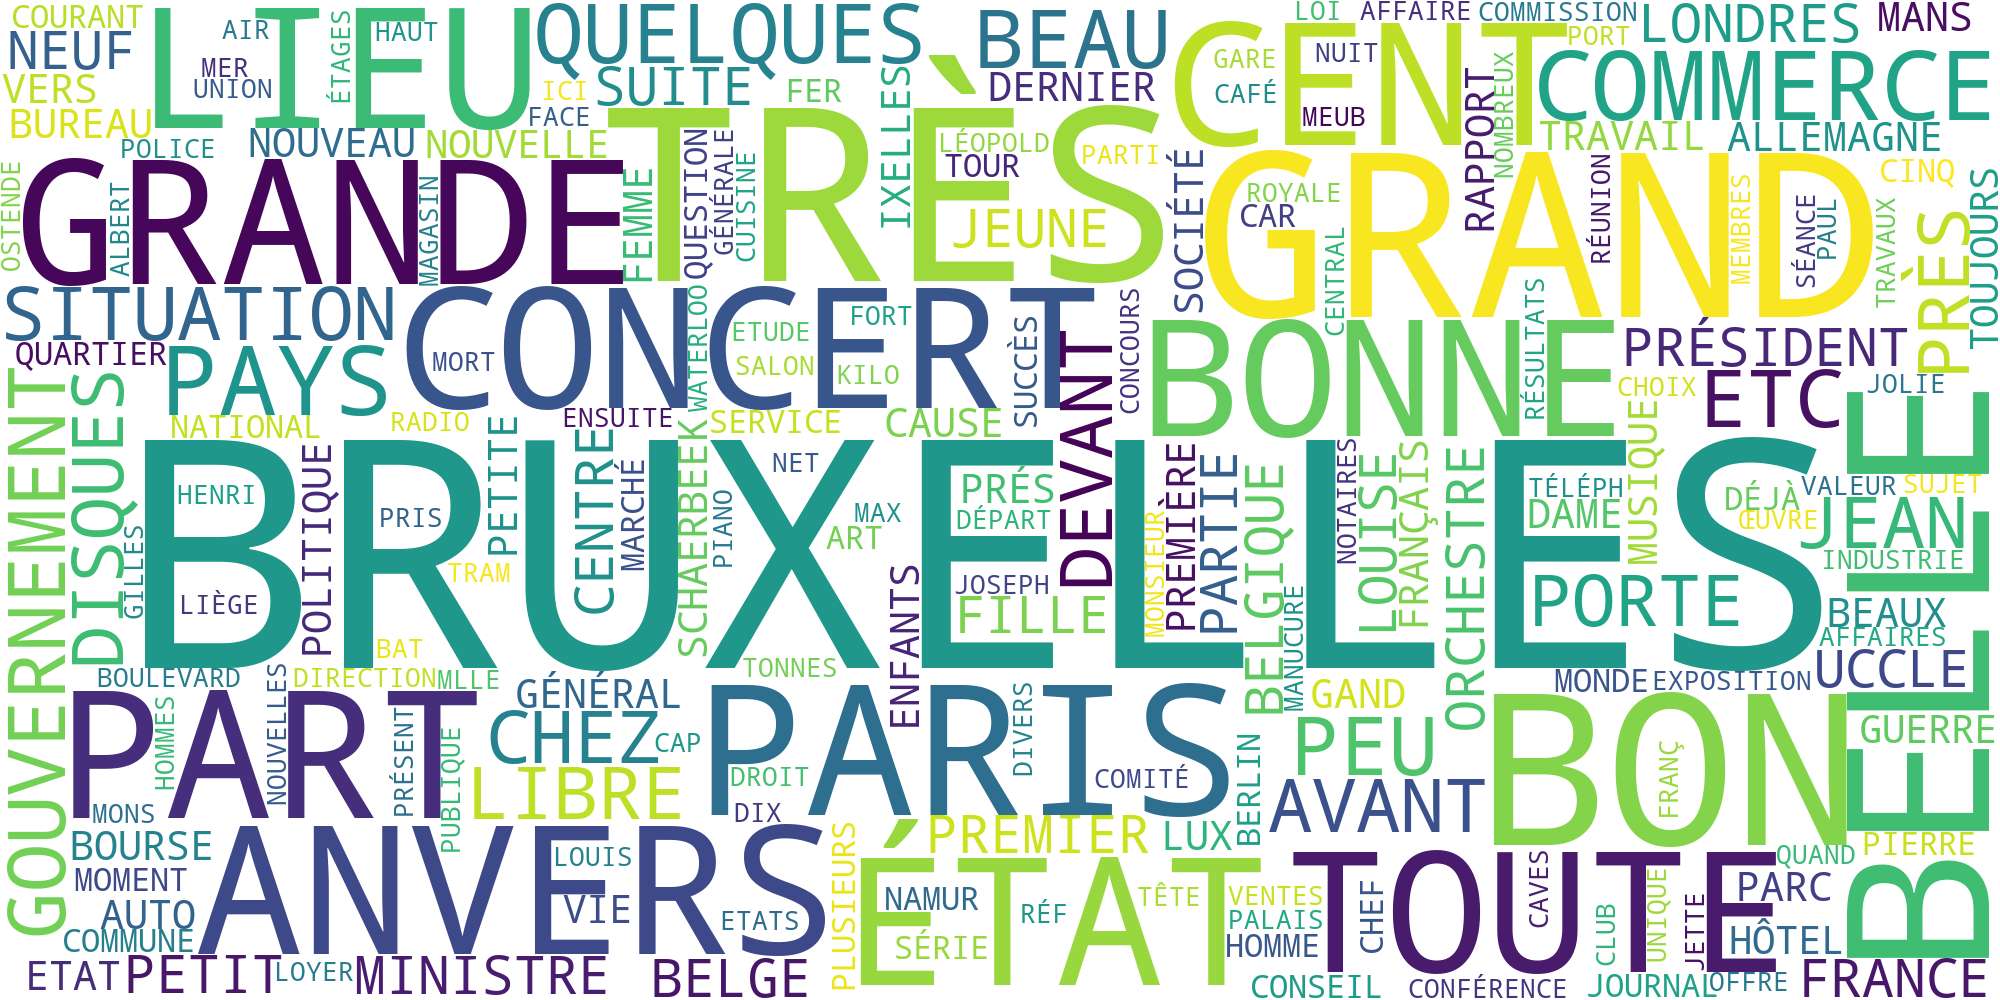

In [26]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))

# Reconnaissance d'entités nommées avec SpaCy

# Reconnaissance d'entités nommées avec SpaCy

La documentation est accessible ici: https://spacy.io/api

## Imports

In [27]:
from collections import defaultdict
import spacy
from spacy.lang.fr.examples import sentences

In [28]:
nlp = spacy.load('fr_core_news_md')

## Exemple sur un corpus de test fourni par SpaCy

In [29]:
# Imprimer le corpus de Spacy
sentences

['Apple cherche à acheter une start-up anglaise pour 1 milliard de dollars',
 "Les voitures autonomes déplacent la responsabilité de l'assurance vers les constructeurs",
 "San Francisco envisage d'interdire les robots coursiers sur les trottoirs",
 'Londres est une grande ville du Royaume-Uni',
 'L’Italie choisit ArcelorMittal pour reprendre la plus grande aciérie d’Europe',
 "Apple lance HomePod parce qu'il se sent menacé par l'Echo d'Amazon",
 "La France ne devrait pas manquer d'électricité cet été, même en cas de canicule",
 'Nouvelles attaques de Trump contre le maire de Londres',
 'Où es-tu ?',
 'Qui est le président de la France ?',
 'Où est la capitale des États-Unis ?',
 'Quand est né Barack Obama ?']

In [30]:
# Isoler la première phrase
sent = sentences[0]
sent

'Apple cherche à acheter une start-up anglaise pour 1 milliard de dollars'

In [31]:
# Traiter la phrase avec Spacy
doc = nlp(sent)

In [32]:
type(doc)

spacy.tokens.doc.Doc

In [33]:
doc.text

'Apple cherche à acheter une start-up anglaise pour 1 milliard de dollars'

In [34]:
doc.to_json()

{'text': 'Apple cherche à acheter une start-up anglaise pour 1 milliard de dollars',
 'ents': [{'start': 0, 'end': 5, 'label': 'ORG'}],
 'sents': [{'start': 0, 'end': 72}],
 'tokens': [{'id': 0,
   'start': 0,
   'end': 5,
   'tag': 'PROPN',
   'pos': 'PROPN',
   'morph': 'Gender=Masc|Number=Sing',
   'lemma': 'Apple',
   'dep': 'nsubj',
   'head': 1},
  {'id': 1,
   'start': 6,
   'end': 13,
   'tag': 'VERB',
   'pos': 'VERB',
   'morph': 'Mood=Ind|Number=Sing|Person=3|Tense=Pres|VerbForm=Fin',
   'lemma': 'cherche',
   'dep': 'ROOT',
   'head': 1},
  {'id': 2,
   'start': 14,
   'end': 15,
   'tag': 'ADP',
   'pos': 'ADP',
   'morph': '',
   'lemma': 'à',
   'dep': 'mark',
   'head': 3},
  {'id': 3,
   'start': 16,
   'end': 23,
   'tag': 'VERB',
   'pos': 'VERB',
   'morph': 'VerbForm=Inf',
   'lemma': 'acheter',
   'dep': 'xcomp',
   'head': 1},
  {'id': 4,
   'start': 24,
   'end': 27,
   'tag': 'DET',
   'pos': 'DET',
   'morph': 'Definite=Ind|Gender=Fem|Number=Sing|PronType=Art'

In [35]:
# Appliquer le test sur toutes les phrases
for sent in sentences:
    doc = nlp(sent)
    entities = []
    for ent in doc.ents:
        entities.append(f"{ent.text} ({ent.label_})")
    if entities:
        print(f"'{doc.text}' contient les entités suivantes : {', '.join(entities)}")
    else:
        print(f"'{doc.text}' ne contient aucune entité")

'Apple cherche à acheter une start-up anglaise pour 1 milliard de dollars' contient les entités suivantes : Apple (ORG)
'Les voitures autonomes déplacent la responsabilité de l'assurance vers les constructeurs' ne contient aucune entité
'San Francisco envisage d'interdire les robots coursiers sur les trottoirs' contient les entités suivantes : San Francisco (LOC)
'Londres est une grande ville du Royaume-Uni' contient les entités suivantes : Londres (LOC), Royaume-Uni (LOC)
'L’Italie choisit ArcelorMittal pour reprendre la plus grande aciérie d’Europe' contient les entités suivantes : L’Italie (LOC), ArcelorMittal (ORG), Europe (LOC)
'Apple lance HomePod parce qu'il se sent menacé par l'Echo d'Amazon' contient les entités suivantes : Apple (ORG), HomePod (MISC), Echo (ORG), Amazon (ORG)
'La France ne devrait pas manquer d'électricité cet été, même en cas de canicule' contient les entités suivantes : La France (LOC)
'Nouvelles attaques de Trump contre le maire de Londres' contient les en

## Appliquer la reconnaissance d'entités nommées sur notre corpus

In [36]:
# Charger le texte
n=1000000
text = open("../tmp/1933.txt", encoding='utf-8').read()[:n]

In [37]:
%%time
# Traiter le texte

doc = nlp(text)

CPU times: total: 52.8 s
Wall time: 53 s


In [38]:
# Compter les entités
people = defaultdict(int)
for ent in doc.ents:
    if ent.label_ == "PER" and len(ent.text) > 3:
        people[ent.text] += 1

In [39]:
# Trier et imprimer

sorted_people = sorted(people.items(), key=lambda kv: kv[1], reverse=True)

for person, freq in sorted_people:
    print(f"{person} apparait {freq} fois dans le corpus")

Rossel apparait 107 fois dans le corpus
Agence Rossel apparait 66 fois dans le corpus
culs apparait 28 fois dans le corpus
chamb apparait 20 fois dans le corpus
Louise apparait 17 fois dans le corpus
Créd apparait 16 fois dans le corpus
atel apparait 15 fois dans le corpus
Brugmann apparait 15 fois dans le corpus
Jard apparait 14 fois dans le corpus
Jean apparait 12 fois dans le corpus
Lechanchy apparait 12 fois dans le corpus
U. S. G. apparait 12 fois dans le corpus
Jette apparait 11 fois dans le corpus
Madou apparait 11 fois dans le corpus
C. A. S. G. apparait 11 fois dans le corpus
Louis XVI apparait 11 fois dans le corpus
Muriel apparait 11 fois dans le corpus
Lizzy apparait 11 fois dans le corpus
Léonora apparait 11 fois dans le corpus
Jardin apparait 10 fois dans le corpus
Chan-Hai-Kouan apparait 9 fois dans le corpus
Reine apparait 9 fois dans le corpus
Marston apparait 9 fois dans le corpus
Roosevelt apparait 8 fois dans le corpus
M. de Valera apparait 8 fois dans le corpus
M. 

Exercice: essayez de lister les lieux (LOC) et les organisations (ORG) les plus mentionnées dans le corpus

In [40]:
places = defaultdict(int)
for ent in doc.ents:
    if ent.label_ == "LOC" and len(ent.text) > 3:
        places[ent.text] += 1


sorted_places = sorted(places.items(), key=lambda kv: kv[1], reverse=True)

for places, freq in sorted_places:
    print(f"{places} apparait {freq} fois dans le corpus")



orgs = defaultdict(int)
for ent in doc.ents:
    if ent.label_ == "ORG" and len(ent.text) > 3:
        orgs[ent.text] += 1


sorted_orgs = sorted(orgs.items(), key=lambda kv: kv[1], reverse=True)

for orgs, freq in sorted_orgs:
    print(f"{orgs} apparait {freq} fois dans le corpus")

Bruxelles apparait 193 fois dans le corpus
Brux apparait 103 fois dans le corpus
Anvers apparait 78 fois dans le corpus
Paris apparait 58 fois dans le corpus
mans apparait 51 fois dans le corpus
w.-c apparait 47 fois dans le corpus
Belgique apparait 34 fois dans le corpus
Gand apparait 31 fois dans le corpus
Nord apparait 31 fois dans le corpus
Cond apparait 31 fois dans le corpus
Genève apparait 29 fois dans le corpus
Londres apparait 28 fois dans le corpus
Uccle apparait 28 fois dans le corpus
Allemagne apparait 26 fois dans le corpus
Bourse apparait 26 fois dans le corpus
Ixelles apparait 23 fois dans le corpus
Agence Rossel apparait 23 fois dans le corpus
Etat apparait 22 fois dans le corpus
A Bruxelles apparait 22 fois dans le corpus
Mons apparait 21 fois dans le corpus
Liège apparait 21 fois dans le corpus
Téléph apparait 20 fois dans le corpus
Midi apparait 19 fois dans le corpus
BRUXELLES apparait 19 fois dans le corpus
Téléphone apparait 18 fois dans le corpus
chauff apparait 

# Sentiment analysis 

## 1. Textblob-FR

Documentation: https://textblob.readthedocs.io/en/dev/

### Imports

In [41]:
from textblob import Blobber
from textblob_fr import PatternTagger, PatternAnalyzer

### Création d'une fonction `get_sentiment`

In [42]:
tb = Blobber(pos_tagger=PatternTagger(), analyzer=PatternAnalyzer())

def get_sentiment(input_text):
    blob = tb(input_text)
    polarity, subjectivity = blob.sentiment
    polarity_perc = f"{100*abs(polarity):.0f}"
    subjectivity_perc = f"{100*subjectivity:.0f}"
    if polarity > 0:
        polarity_str = f"{polarity_perc}% positive"
    elif polarity < 0:
        polarity_str = f"{polarity_perc}% negative"
    else:
        polarity_str = "neutral"
    if subjectivity > 0:
        subjectivity_str = f"{subjectivity_perc}% subjective"
    else:
        subjectivity_str = "perfectly objective"
    print(f"This text is {polarity_str} and {subjectivity_str}.")

### Analyser le sentiment d'une phrase

In [43]:
get_sentiment("Zingara, l’auteur de l’attentat contre le président Roosevelt, a été condamné à mort.")
get_sentiment("Adolf Hitler était du nombre de ceux qui s’interrogeaient ainsi avec angoisse.")
get_sentiment("Nous sommes prêts à tendre la main au gouvernement allemand, à condition que ce soit sur le terrain de la loyauté et de la rectitude.")
get_sentiment("Si quelqu’un avait déclaré, il y a quelques années, qu’une doctrine basée sur ces idées serait prise au sérieux en Allemagne, on aurait probablement bien ri à l’étranger de pareilles extravagances.")
get_sentiment("Pour faire des économies, le gouvernement taille à tort et à travers.")
get_sentiment("Les uns attribuent cette inquiétude à l’insuccès manifeste du programme de redressement national, les autres aux indices décevants de l’activité industrielle et commerciale.")
get_sentiment("Le malheureux enfant a succombé après quelques heures d’horribles souffrances.")
get_sentiment("De plus dans un brillant intermède, notre compatriote Berthe Bovy Interprétera entre autres, son succès si personnel - « La Jasante de la vieille », de Jehan Rictus.")
get_sentiment("La réunion de propagande a obtenu un beau succès populaire.")
get_sentiment("Pains d’épices au miel fin d’ancienne réputation.")

This text is neutral and perfectly objective.
This text is neutral and perfectly objective.
This text is 14% positive and 13% subjective.
This text is 7% positive and 31% subjective.
This text is neutral and perfectly objective.
This text is neutral and 4% subjective.
This text is 65% negative and 85% subjective.
This text is 26% positive and 26% subjective.
This text is 65% positive and 65% subjective.
This text is 3% negative and 8% subjective.


In [44]:
get_sentiment("Zingara, l’auteur de l’attentat contre le président Roosevelt, a été condamné à mort.")
get_sentiment("Adolf Hitler était du nombre de ceux qui s’interrogeaient ainsi avec angoisse.")
get_sentiment("Nous sommes prêts à tendre la main au gouvernement allemand, à condition que ce soit sur le terrain de la loyauté et de la rectitude.")
get_sentiment("Si quelqu’un avait déclaré, il y a quelques années, qu’une doctrine basée sur ces idées serait prise au sérieux en Allemagne, on aurait probablement bien ri à l’étranger de pareilles extravagances.")
get_sentiment("Pour faire des économies, le gouvernement taille à tort et à travers.")
get_sentiment("Les uns attribuent cette inquiétude à l’insuccès manifeste du programme de redressement national, les autres aux indices décevants de l’activité industrielle et commerciale.")
get_sentiment("Le malheureux enfant a succombé après quelques heures d’horribles souffrances.")
get_sentiment("De plus dans un brillant intermède, notre compatriote Berthe Bovy Interprétera entre autres, son succès si personnel - « La Jasante de la vieille », de Jehan Rictus.")
get_sentiment("La réunion de propagande a obtenu un beau succès populaire.")
get_sentiment("Pains d’épices au miel fin d’ancienne réputation.")

This text is neutral and perfectly objective.
This text is neutral and perfectly objective.
This text is 14% positive and 13% subjective.
This text is 7% positive and 31% subjective.
This text is neutral and perfectly objective.
This text is neutral and 4% subjective.
This text is 65% negative and 85% subjective.
This text is 26% positive and 26% subjective.
This text is 65% positive and 65% subjective.
This text is 3% negative and 8% subjective.


## 2. Utilisation de transformers

Documentation: https://github.com/TheophileBlard/french-sentiment-analysis-with-bert

**!!** Si le code ne tourne pas sur votre machine, vous pouvez le tester directement sur Google Colab en utilisant [ce lien](https://colab.research.google.com/github/TheophileBlard/french-sentiment-analysis-with-bert/blob/master/colab/french_sentiment_analysis_with_bert.ipynb) **!!**

Le modèle peut également être testé en ligne sur [HuggingFace](https://huggingface.co/tblard/tf-allocine)

Note : `transformers` v5 a supprimé le support TensorFlow. On utilise donc ici `philschmid/pt-tblard-tf-allocine`, un portage PyTorch du même modèle, avec les classes `AutoModelForSequenceClassification` (au lieu de `TFAutoModelForSequenceClassification`).

### Installation des librairies et imports

In [45]:
!uv pip install sentencepiece
!uv pip install transformers>=5.19.0
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import pipeline

Using Python 3.11.5 environment at: C:\Users\gaeta\tac\.venv
Checked 1 package in 44ms
Using Python 3.11.5 environment at: C:\Users\gaeta\tac\.venv
Checked 1 package in 388ms
c:\Users\gaeta\tac\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Chargement du modèle

In [46]:
tokenizer = AutoTokenizer.from_pretrained("philschmid/pt-tblard-tf-allocine")
model = AutoModelForSequenceClassification.from_pretrained("philschmid/pt-tblard-tf-allocine")

sentiment_analyser = pipeline('sentiment-analysis', model=model, tokenizer=tokenizer)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 21939.70it/s]


### Analyser le sentiment d'une phrase

In [47]:
get_sentiment("Zingara, l’auteur de l’attentat contre le président Roosevelt, a été condamné à mort.")
get_sentiment("Adolf Hitler était du nombre de ceux qui s’interrogeaient ainsi avec angoisse.")
get_sentiment("Nous sommes prêts à tendre la main au gouvernement allemand, à condition que ce soit sur le terrain de la loyauté et de la rectitude.")
get_sentiment("Si quelqu’un avait déclaré, il y a quelques années, qu’une doctrine basée sur ces idées serait prise au sérieux en Allemagne, on aurait probablement bien ri à l’étranger de pareilles extravagances.")
get_sentiment("Pour faire des économies, le gouvernement taille à tort et à travers.")
get_sentiment("Les uns attribuent cette inquiétude à l’insuccès manifeste du programme de redressement national, les autres aux indices décevants de l’activité industrielle et commerciale.")
get_sentiment("Le malheureux enfant a succombé après quelques heures d’horribles souffrances.")
get_sentiment("De plus dans un brillant intermède, notre compatriote Berthe Bovy Interprétera entre autres, son succès si personnel - « La Jasante de la vieille », de Jehan Rictus.")
get_sentiment("La réunion de propagande a obtenu un beau succès populaire.")
get_sentiment("Pains d’épices au miel fin d’ancienne réputation.")

This text is neutral and perfectly objective.
This text is neutral and perfectly objective.
This text is 14% positive and 13% subjective.
This text is 7% positive and 31% subjective.
This text is neutral and perfectly objective.
This text is neutral and 4% subjective.
This text is 65% negative and 85% subjective.
This text is 26% positive and 26% subjective.
This text is 65% positive and 65% subjective.
This text is 3% negative and 8% subjective.


In [ ]:
get_sentiment("Zingara, l’auteur de l’attentat contre le président Roosevelt, a été condamné à mort.")
get_sentiment("Adolf Hitler était du nombre de ceux qui s’interrogeaient ainsi avec angoisse.")
get_sentiment("Nous sommes prêts à tendre la main au gouvernement allemand, à condition que ce soit sur le terrain de la loyauté et de la rectitude.")
get_sentiment("Si quelqu’un avait déclaré, il y a quelques années, qu’une doctrine basée sur ces idées serait prise au sérieux en Allemagne, on aurait probablement bien ri à l’étranger de pareilles extravagances.")
get_sentiment("Pour faire des économies, le gouvernement taille à tort et à travers.")
get_sentiment("Les uns attribuent cette inquiétude à l’insuccès manifeste du programme de redressement national, les autres aux indices décevants de l’activité industrielle et commerciale.")
get_sentiment("Le malheureux enfant a succombé après quelques heures d’horribles souffrances.")
get_sentiment("De plus dans un brillant intermède, notre compatriote Berthe Bovy Interprétera entre autres, son succès si personnel - « La Jasante de la vieille », de Jehan Rictus.")
get_sentiment("La réunion de propagande a obtenu un beau succès populaire.")
get_sentiment("Pains d’épices au miel fin d’ancienne réputation.")

This text is neutral and perfectly objective.
This text is neutral and perfectly objective.
This text is 14% positive and 13% subjective.
This text is 7% positive and 31% subjective.
This text is neutral and perfectly objective.
This text is neutral and 4% subjective.
This text is 65% negative and 85% subjective.
This text is 26% positive and 26% subjective.
This text is 65% positive and 65% subjective.
This text is 3% negative and 8% subjective.


: 